


# Testing robustness to input noise (`p_flip`)

The model trained (notebook 11) on patterns with `p_flip = 0.01` is evaluated as the
stochasticity of the **trigger** grows: each call of the pattern generator balanced-flips
a fraction `p_flip` of the frozen target's bits, so the input trigger deviates more and
more from the stored memory while keeping its firing rate. A healthy HD-SNN should
degrade gracefully - retrieval is a *pattern-completion* problem, tolerant to corrupted
cues.

## Notebook summary

### Pipeline
1. Load the trained vanilla model on the stochastic generator.
2. Single-noise probe at `p_flip = 0.18` (raster + F1 on the evoked window).
3. Sweep `p_flip` in `N_scan=14` values x `N_cv=11` seeded repetitions -> `<datetag>_noise.npz`,
    plot F1 (mean, 5%-95% beta quantiles) vs bit-flip probability (`p_flip_score.pdf`).
4. Theory: the $F_1$ of a motif-wise ignition of the replay (`get_f1_ignition`, anchored on the
     noise-free precision and recall), overlaid on both score figures.
5. Control condition: **fine-tune** the vanilla model (`learn_model`) at each `p_flip`
     -> `<datetag>_noise_retrain.npz`, and overlay (`p_flip_retrain_score.pdf`).

### Main outputs
- caches `<datetag>_noise.npz` (fixed weights) and `<datetag>_noise_retrain.npz` (fine-tuned);
- figures `p_flip_target.pdf` (raster), `p_flip_score.pdf`, `p_flip_retrain_score.pdf`.

### Notes
- Same evoked-window convention as notebook 11 (`spikes[..., N_pretime+num_delay : ]` vs
     `frozen_target[..., num_delay :]`).
- Repetitions are seeded nb 20-style (`pattern_object(seed=...)`, `get_input_spikes(seed=...)`,
     `seed += 1` per repetition) so the `N_cv` realisations are reproducible; the
     response is scored against the clean `frozen_target`, so the sweep measures
     pattern completion from a degraded cue. `scores_np` is `(N_scan, N_cv)`, saved
     after each scan point (crash-resumable).
- The retrain control fine-tunes the vanilla checkpoint (`load` then `learn_model`, so it
     starts from weights trained at `p_flip = 0.01`) once per `p_flip` (learning outside the `i_cv` loop),
     then evaluates it `N_cv` times under the same protocol.
- The theory curve (`get_f1_ignition`) is a mean-field approximation of the pseudo-inverse readout: it ignores
     the membrane leak, the network's own activity during the trigger and the departure of the
     trained weights from the initialisation; the only measured inputs are the noise-free
     precision and recall.

<!-- MNESIS-annotated -->

In [1]:
# torch, numpy, cache dir, RECOMPUTE switch, scorers and plotting helpers come from
# mnesis_boilerplate; the model/algorithm and the pattern generator from mnesis_chains.
from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, Params, SubplotParams
from mnesis_boilerplate import printfig, get_scores, get_f1score, get_beta_errorbar, trange
from mnesis_boilerplate import get_f1_ignition
from mnesis_chains import StochasticSpikingPattern, HD_SNN, load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


## Loading the trained model

The model is loaded with the default `Params()` (`p_flip = 0.01`, the training regime);
the same `seed` reproduces the *frozen* target, and the per-call `p_flip` of the
generator is overridden below (`hd.pattern_object.opt.p_flip = ...`) for the probes.

In [2]:
opt = Params()
hd = HD_SNN(opt, StochasticSpikingPattern())
hd.net.to(hd.opt.device)
model_filename = data_cache / f"{hd.opt.datetag}_vanilla.pth"
model_state_dict = torch.load(model_filename, map_location=torch.device(hd.opt.device))
hd.net.load_state_dict(model_state_dict)
hd.net.eval()
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


## Single retrieval trial under noise

Trigger `p_flip=0.18`, well above the training regime (`p_flip=0.01`): the reference motif
(`i_pattern=0`) is read back through the usual evoked-window slices and scored against the
frozen target.

### Raster of the noisy-trial retrieval

Same legend as notebook 11: green `x` trigger (noisy first `num_delay` ms), open red `o`
frozen target, blue `+` evoked response; dashed verticals at `N_pretime` and `N_pretime+num_delay`.

In [3]:
with torch.no_grad():
   hd.pattern_object.opt.p_flip = .18
   target = hd.pattern_object.frozen_target # noise-free reference, scored against
   cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
   target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
   input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
   _, _, spikes = hd.forward_pass(input_spikes)
   spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
   target_evoked = target[:, :, hd.opt.num_delay:]

   precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
   print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.708	 recall = 0.512	 f1_score = 0.594 


Saving as ../figures/p_flip_target.pdf
Saving as ../figures/p_flip_target.png
Saving as ../figures/p_flip_target.svg


(torch.Size([16, 1024, 1100]), 265.0, 140.0)

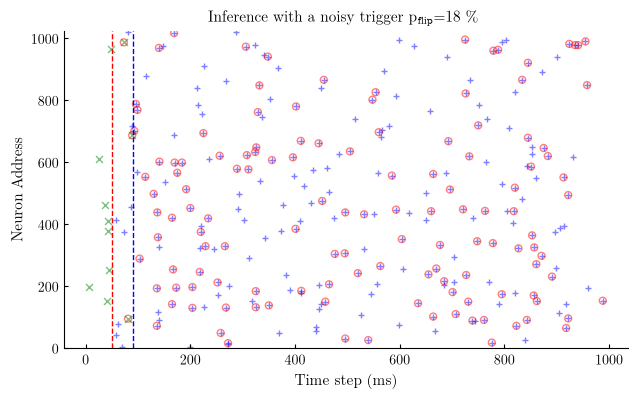

In [4]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
ax.set_title(rf"Inference with a noisy trigger $p_{{\text{{flip}}}}$={hd.pattern_object.opt.p_flip*100:.0f} % ")
printfig(fig, 'p_flip_target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: fixed weights, increasing trigger noise

`get_scores_noise`: for `N_scan` values of `p_flip` (linspace 0..1) and `N_cv`
independent realisations each, trigger the network and score the evoked window; the
trigger itself is corrupted (`target_ = pattern_object(seed=seed)`) while scoring still uses the
clean stored target - i.e. classic **pattern completion from a degraded cue**.
Results cached as `<datetag>_noise.npz` (arrays `p_flip`, `scores_np`) under the standard
`.lock` protocol.

In [5]:
# Fixed-weights sweep with N_cv repetitions per scan point: each repetition is an
# independent stochastic cue (the same seed drives the flips of pattern_object and the
# spontaneous pad of get_input_spikes - nb 20''s seed += 1 convention), scored against the
# clean frozen_target: classic pattern completion from a degraded cue. The cache is
# written after every scan point (with an n_done sentinel) so an interrupted run can
# resume from the file and a partial file is never mistaken for a complete one.

def get_scores_noise(N_scan=opt.N_scan, N_cv=opt.N_cv):
    p_flip = np.linspace(0, 1, N_scan, endpoint=True)
    scores_np = np.zeros((N_scan, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_scan in trange(N_scan):
        for i_cv in range(N_cv):
            with torch.no_grad():
                hd.pattern_object.opt.p_flip = p_flip[i_scan]
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, seed=seed)
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, p_flip=p_flip, scores_np=scores_np, n_done=i_scan + 1) # incremental save

    return p_flip, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_noise.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    p_flip = data['p_flip']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
        ##################
        p_flip, scores_np = get_scores_noise()
        ##################
        np.savez(npy_filename, p_flip=p_flip, scores_np=scores_np, n_done=opt.N_scan)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score file not found: ../cached_data/2026-09-07_noise.npz, evaluating the score.


100%|██████████| 14/14 [03:25<00:00, 14.67s/it]


In [6]:
# Reload the fixed-weights sweep (with named keys, tolerant of the n_done field).

data = np.load(npy_filename)
p_flip, scores_np = data['p_flip'], data['scores_np']

## Expected F1 from theory

Two references are computed from the parameters; only the second one, the ignition of the replay,
is overlaid on the measured curves.

**Noisy copy (no pattern completion).** A balanced flip keeps a spike of the motif with
probability $q = 1 - p_\mathrm{flip}\,(1 - p_A)$, where $p_\mathrm{flip}$ is the bit-flip
probability and $p_A$ the firing probability of the motif, and turns an empty bin into a spike
with probability $p_\mathrm{flip}\,p_A$. The corrupted motif thus has an expected precision and
recall both equal to $q$:

$$F_1^\mathrm{copy} = 1 - p_\mathrm{flip}\,(1 - p_A),$$

a straight line from 1 down to chance level ($F_1 = p_A \approx 0$) at $p_\mathrm{flip} = 1$:
the score of a readout that would copy the corrupted motif as is.

**Ignition of the replay.** With the minimum-norm (pseudo-inverse) readout, each spike of a motif
is supported by the $K$ spikes of that motif in its spiking-motif window ($N$ neurons by $D$ time
bins), with equal weights: the membrane potential reaches 1 when all of them are present and $k/K$
when only $k$ of them survive, while a spurious spike falls on a near-zero weight (the motifs are
sparse). $K$ follows a Poisson law of mean $\lambda = p_A N D$. The first evoked spikes are driven
by the trigger alone and, $\lambda$ being small, share the same few supporting spikes: the replay
of a motif ignites as a whole when $k \geq \lceil \vartheta K \rceil$, with $\vartheta$ the firing
threshold, and then sustains itself; otherwise it dies out. The ignition probability is

$$R(p_\mathrm{flip}) = \sum_{K \geq 1} \frac{e^{-\lambda} \lambda^K}{K!} \sum_{k = \lceil \vartheta K \rceil}^{K} \binom{K}{k}\, q^k (1 - q)^{K - k}.$$

An ignited motif is replayed with the noise-free precision $\pi_0$ and recall $r_0$, and a silent
one only adds false negatives. Per spike of the motifs, the true positives are $R\, r_0$, the false
negatives $1 - R\, r_0$ and the false positives $R\, r_0 (1/\pi_0 - 1)$, hence

$$F_1^\mathrm{ign} = \frac{2\, R\, r_0}{1 + R\, r_0 / \pi_0}.$$

The threshold is the LIF threshold of the network, not a fitted value; only $\pi_0$ and $r_0$ are
measured, with the noise-free trigger.

| symbol | name in the code | default value | role |
|---|---|---|---|
| $p_\mathrm{flip}$ | `p_flip` | swept in $[0, 1]$ (training: 0.01) | bit-flip probability of the trigger |
| $p_A$ | `p_A` | $1.6 \times 10^{-4}$ per 1 ms bin (0.16 Hz) | firing probability of the motif |
| $N$ | `N_neuron` | 1024 | number of neurons |
| $D$ | `num_delay` | 41 bins (41 ms) | width of the spiking-motif window and of the trigger |
| $\vartheta$ | `lif_threshold` | 0.75 | firing threshold, relative to the membrane potential reached on the motif |
| $\lambda$ | `p_A * N_neuron * num_delay` | 6.72 | mean number of spikes supporting a spike of the motif |
| $q$ | - | $1 - p_\mathrm{flip}(1 - p_A)$ | probability that a spike of the motif survives the flips |
| $R$ | - | - | probability that the replay of a motif ignites |
| $\pi_0$, $r_0$ | `precision_0`, `recall_0` | measured at $p_\mathrm{flip} = 0$ | noise-free precision and recall of the replay |

The cell below measures $\pi_0$ and $r_0$ with the first repetition of the sweep protocol at
$p_\mathrm{flip} = 0$ (same seed), evaluates the ignition curve, and reports the RMS error of the
ignition model on the sweep. In both score figures, the dashed black line is $F_1^\mathrm{ign}$.

In [7]:
# Noise-free precision and recall of the replay (first repetition of the sweep protocol at
# p_flip = 0, same seed): the only measured inputs of the ignition model.

with torch.no_grad():
    hd.pattern_object.opt.p_flip = 0.
    target_ = hd.pattern_object(seed=hd.opt.seed)
    _, _, spikes = hd.forward_pass(hd.get_input_spikes(target=target_, seed=hd.opt.seed))
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    precision_0, recall_0, f1_score_0 = [score.item() for score in get_scores(spikes_evoked, target_evoked)]
print(f'p_flip = 0: precision = {precision_0:.3f}\t recall = {recall_0:.3f}\t f1_score = {f1_score_0:.3f}')

theory_dict = dict(p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                   lif_threshold=opt.lif_threshold, precision_0=precision_0, recall_0=recall_0)
p_flip_theory = np.linspace(0, 1, 201)
f1_ignition_theory = get_f1_ignition(p_flip_theory, **theory_dict)
rmse = np.sqrt(np.mean((get_f1_ignition(p_flip, **theory_dict) - scores_np.mean(axis=1))**2))
print(f'lambda = p_A N D = {opt.p_A * opt.N_neuron * opt.num_delay:.2f} supporting spikes; '
      f'RMS error of the ignition model on the sweep = {rmse:.3f}')

p_flip = 0: precision = 0.877	 recall = 0.825	 f1_score = 0.850
lambda = p_A N D = 6.72 supporting spikes; RMS error of the ignition model on the sweep = 0.040


In [8]:
# Layout constants for the scan figures (spine styling).
subplotpars_scan = SubplotParams(left=0.125, right=.95, bottom=0.25, top=.975)

Saving as ../figures/p_flip_score.pdf
Saving as ../figures/p_flip_score.png
Saving as ../figures/p_flip_score.svg


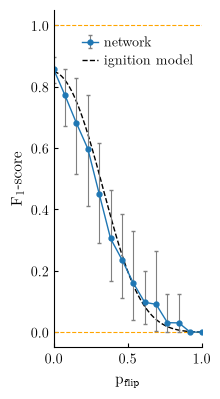

In [ ]:
# $F_1$ as a function of the bit-flipping probability $p_\mathrm{flip}$: mean and 5%-95% quantiles of a beta fit over N_cv realisations,
# against the F1 expected from the ignition model (dashed).

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], p_flip[0], p_flip[-1], 'orange', ls='--', lw=0.8)
    ax.plot(p_flip_theory, f1_ignition_theory, color='k', ls='--', label='ignition model')
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(p_flip, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0, label='MNESIS')
    ax.set_xlabel(r"$p_\mathrm{flip}$")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(p_flip[0], p_flip[-1])
    ax.set_ylim(-0.05, 1.05)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc='upper right', bbox_to_anchor=(1., .95), # network first, below the F1 = 1 line
              handlelength=1.2, handletextpad=0.4, borderaxespad=0.2, labelspacing=0.3)

    printfig(fig, 'p_flip_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)


## Control: fine-tune the network for each noise level to improve WM

If graceful degradation is caused by training at `p_flip=0.01` only, training a *matched*
model per noise level should push the whole F1 curve up. Hypothesis under test:
robustness to corrupted cues is learnable (data augmentation at the right level).
Each scan point fine-tunes the vanilla readout (`load` then `learn_model`, `verbose=False`)
on a `Params` instantiated with that `p_flip`, then evaluates it N_cv times with the same protocol as
the fixed-weights sweep. Cached as `<datetag>_noise_retrain.npz`.

In [ ]:
# Control condition: one model per p_flip, fine-tuned from the vanilla checkpoint by
# learn_model at that noise level (learning hoisted out of the CV loop, with local variables so the global hd/opt/model_filename are left untouched),
# then evaluated N_cv times under the same seeded protocol and the same frozen-target
# reference as the fixed-weights sweep. Incremental save with an n_done sentinel.

def get_scores_retrain_noise(N_scan=opt.N_scan, N_cv=opt.N_cv):
    p_flip = np.linspace(0., 1., N_scan, endpoint=True)
    scores_np = np.zeros((N_scan, N_cv))
    i_start = 0
    if npy_filename.exists(): # resume: each scan point re-seeds itself (Params.__post_init__),
        data = np.load(npy_filename) # so cached rows are valid; continue after n_done
        if data['scores_retrain_np'].shape == (N_scan, N_cv):
            scores_np = data['scores_retrain_np']
            i_start = int(data['n_done']) if 'n_done' in data else N_scan
    # base seed of the first scan point left to compute, incremented per repetition (nb 20 convention)
    seed = opt.seed + opt.N_cv * i_start
    for i_scan in trange(i_start, N_scan):
        ##################
        opt_local = Params(p_flip=p_flip[i_scan])
        model_filename_local = data_cache / f"{opt_local.datetag}_vanilla.pth"
        hd_local = load(opt_local, model_filename_local)
        # REDUNDANT: hd_local.pattern_object.opt.p_flip = p_flip[i_scan]
        hd_local.learn_model(verbose=False)
        ##################
        target_evoked = hd_local.pattern_object.frozen_target[:, :, hd_local.opt.num_delay:]
        for i_cv in range(N_cv):
            with torch.no_grad():
                target_ = hd_local.pattern_object(seed=seed)
                input_spikes = hd_local.get_input_spikes(target=target_, seed=seed)
                _, _, spikes = hd_local.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd_local.opt.N_pretime+hd_local.opt.num_delay):(hd_local.opt.N_time+hd_local.opt.N_pretime)]

                scores_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, p_flip_retrain=p_flip, scores_retrain_np=scores_np, n_done=i_scan + 1) # incremental save

    return p_flip, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_noise_retrain.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    p_flip_retrain = data['p_flip_retrain']
    scores_retrain_np = data['scores_retrain_np']
    if data['scores_retrain_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (int(data['n_done']) != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, resuming.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
         ##################
        p_flip_retrain, scores_retrain_np = get_scores_retrain_noise()
         ##################
        np.savez(npy_filename, p_flip_retrain=p_flip_retrain, scores_retrain_np=scores_retrain_np, n_done=opt.N_scan)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score file not found: ../cached_data/2026-09-07_noise_retrain.npz, evaluating the score.


  0%|          | 0/14 [00:00<?, ?it/s]

In [ ]:
# Reload the retrain control (robust to the scan cell having taken the locked branch).

try:
    data = np.load(npy_filename)
    p_flip_retrain, scores_retrain_np = data['p_flip_retrain'], data['scores_retrain_np']
    print(f"Retrain scores loaded from {npy_filename}")
except FileNotFoundError:
    p_flip_retrain, scores_retrain_np = None, None
    print(f"Retrain score file not available yet: {npy_filename} (locked or not computed).")

In [ ]:
# Overlay fixed-weights (blue) vs fine-tuned (red) $F_1$ vs $p_\mathrm{flip}$, and the ignition model (dashed).

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], p_flip[0], p_flip[-1], 'orange', ls='--', lw=0.8)
    ax.plot(p_flip_theory, f1_ignition_theory, color='k', ls='--')
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(p_flip, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0, label='fixed weights')
    if scores_retrain_np is not None:
        mean_retrain, yerr_retrain = get_beta_errorbar(scores_retrain_np)
        ax.errorbar(p_flip_retrain, mean_retrain, yerr=yerr_retrain, fmt='o',
                    color='tab:red', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                    markersize=3.5, linestyle='solid', linewidth=1.0, label='fine-tuned')
    ax.set_xlabel(r"$p_\mathrm{flip}$")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(p_flip[0], p_flip[-1])
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc='best')

    printfig(fig, 'p_flip_retrain_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
